# Single File Validation with HRVAS-Python
This notebook validates the processing pipeline for a single IBI file by:
1. Loading the raw data and configuration.
2. Visualizing each step of preprocessing (Artifact Correction -> Detrending).
3. Analyzing the signal (Time Domain) using Cleaned IBI (nIBI) as per HRVAS standard.
4. Comparing the results against the MATLAB Ground Truth.

**Note:** Discrepancies in SDNN are expected if the Ground Truth file was generated using Detrended data, which differs from the standard 'Cleaned IBI' usage for time domain measures.


In [9]:
import sys
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Add project root to path
sys.path.append(os.path.abspath('../../..'))

from hrvas.io import load_ibi
from hrvas.config import HRVASConfig
from hrvas.preprocessing import detrend_ibi, DetrendMethod
from hrvas.preprocessing.artifact import detect_outliers, replace_outliers, DetectionMethod, ReplacementMethod
from hrvas.analysis.time_domain import calculate_standard_metrics

# Setup plotting
plt.style.use('ggplot')
%matplotlib inline


In [10]:
# Define Paths
VALIDATION_DIR = '../reference_set'
DATA_DIR = os.path.join(VALIDATION_DIR, 'data')
SETTINGS_FILE = os.path.join(VALIDATION_DIR, 'settings.yaml')
GT_FILE = os.path.join(VALIDATION_DIR, 'ground_truth.xlsx')

# Select a sample file
FILENAME = 'control_01.ibi'
FILEPATH = os.path.join(DATA_DIR, FILENAME)

print(f"Analyzing: {FILENAME}")


Analyzing: control_01.ibi


In [11]:
# Load Configuration
config = HRVASConfig.from_yaml(SETTINGS_FILE)
print("Configuration Loaded")
print(f"Preprocessing Config: Detrend={config.preprocessing.detrending.method}")


Configuration Loaded
Preprocessing Config: Detrend=Smoothness Priors


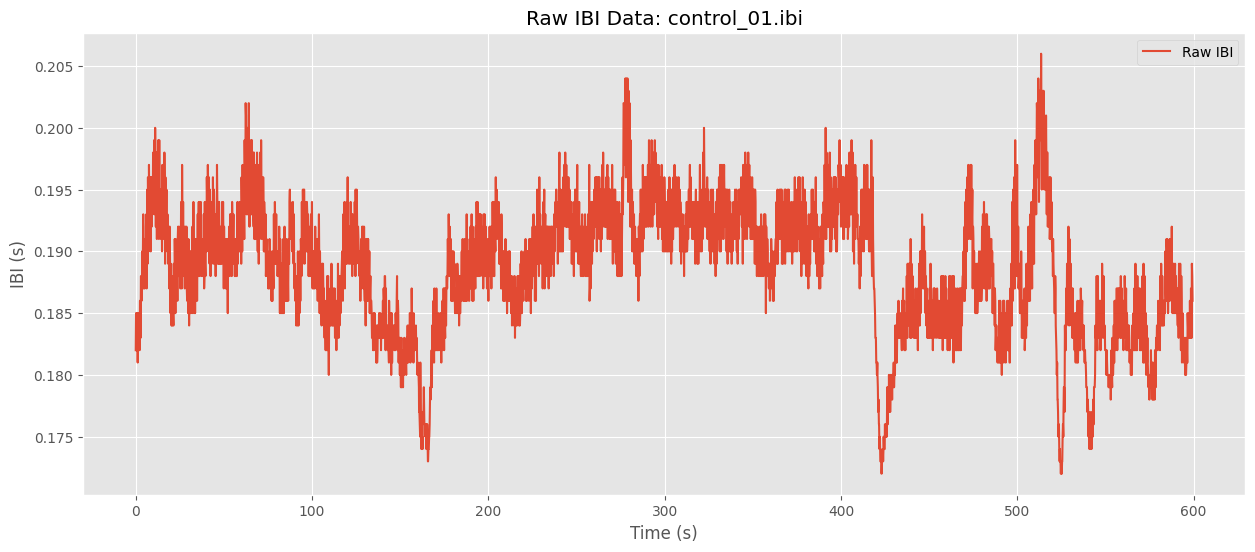

In [12]:
# Load IBI Data
df = load_ibi(FILEPATH, header_row=None)
time_raw = df['Time'].to_numpy()
ibi_raw = df['IBI'].to_numpy()

plt.figure(figsize=(15, 6))
plt.plot(time_raw, ibi_raw, label='Raw IBI')
plt.title(f'Raw IBI Data: {FILENAME}')
plt.xlabel('Time (s)')
plt.ylabel('IBI (s)')
plt.legend()
plt.show()


## Preprocessing Step 1: Artifact Correction (on Raw IBI)
MATLAB Pipeline Reference: `correctEctopic` is applied first to the Raw IBI using the settings provided.


PERCENT Outliers (20.0%): 0
SD Outliers (3.0 sigma): 13
Total Unique Outliers: 13
Cleaned signal length: 3167 beats (nIBI)


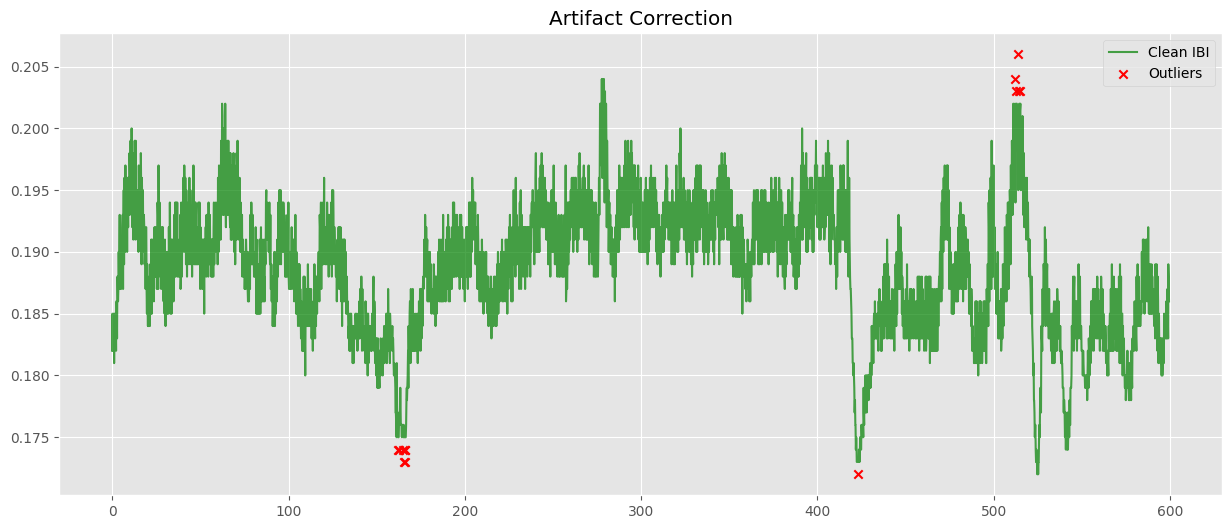

In [13]:
# Step A: Artifact Detection
art_det = config.preprocessing.artifact_detection
mask = np.zeros(len(ibi_raw), dtype=bool)

if art_det.percent.enabled:
    limit = art_det.percent.threshold / 100.0
    m = detect_outliers(ibi_raw, method=DetectionMethod.PERCENT, limit=limit)
    mask = mask | m
    print(f"PERCENT Outliers ({limit*100}%): {np.sum(m)}")

if art_det.std_dev.enabled:
    limit = art_det.std_dev.threshold
    m = detect_outliers(ibi_raw, method=DetectionMethod.SD, limit=limit)
    mask = mask | m
    print(f"SD Outliers ({limit} sigma): {np.sum(m)}")
    
print(f"Total Unique Outliers: {np.sum(mask)}")

# Step B: Replacement
rep_conf = config.preprocessing.artifact_replace
rep_method_enum = ReplacementMethod.REMOVE
if rep_conf.method == "Mean": rep_method_enum = ReplacementMethod.MEAN
elif rep_conf.method == "Median": rep_method_enum = ReplacementMethod.MEDIAN
elif rep_conf.method == "Spline": rep_method_enum = ReplacementMethod.SPLINE

time_clean, ibi_clean = replace_outliers(
    time_raw, 
    ibi_raw, 
    outliers=mask, 
    method=rep_method_enum
)
print(f"Cleaned signal length: {len(ibi_clean)} beats (nIBI)")

if np.any(mask):
    plt.figure(figsize=(15, 6))
    plt.plot(time_clean, ibi_clean, label='Clean IBI', color='green', alpha=0.7)
    plt.scatter(time_raw[mask], ibi_raw[mask], color='red', label='Outliers', marker='x')
    plt.title('Artifact Correction')
    plt.legend()
    plt.show()


## Preprocessing Step 2: Detrending (on Cleaned IBI)
Detrended IBI (`dIBI`) is used primarily for frequency domain analysis. Here we calculate it for reference.


Detrending Method: Smoothness Priors
Sampling Rate for Smoothing: 10.0 Hz


/Users/johnramshur/Documents/_projects/hrvas-python/hrvas/preprocessing/detrend/smoothness_priors.py:37: SparseEfficiencyWarning: spsolve requires A be CSC or CSR matrix format
  trend_reg = spsolve(A, y_reg)


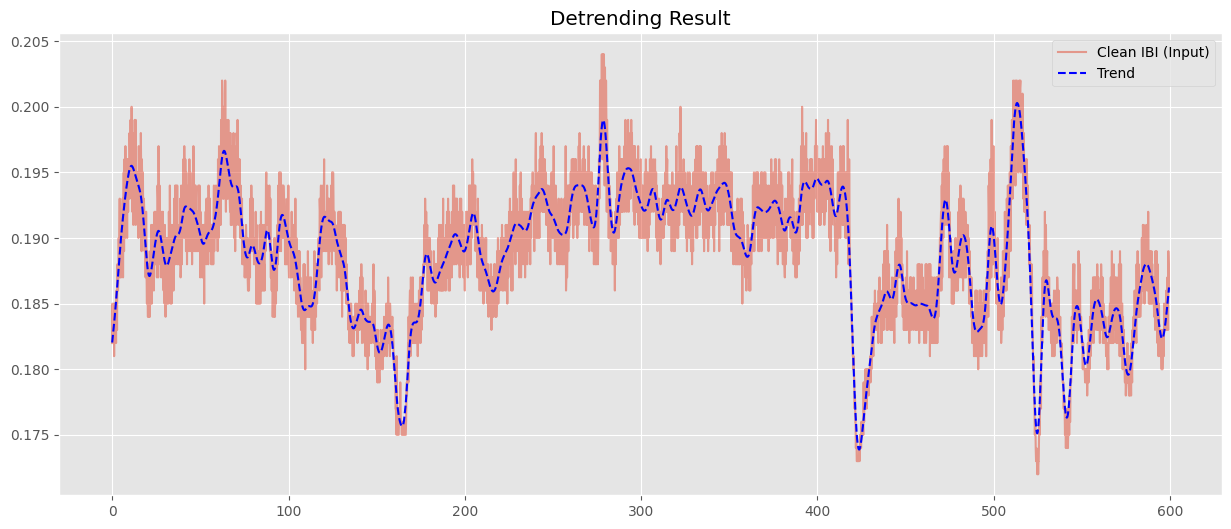

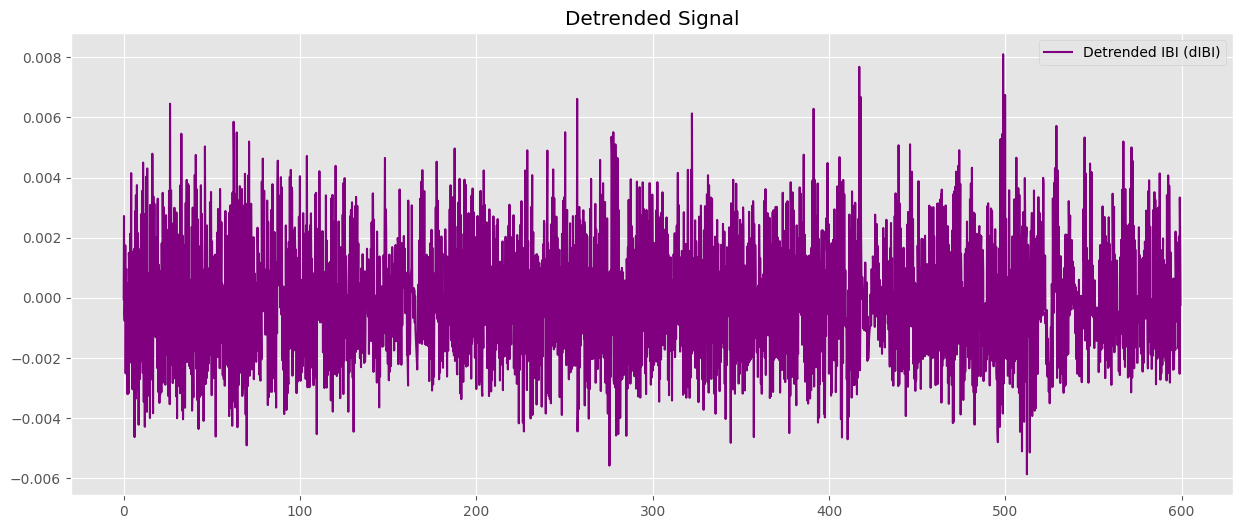

In [14]:
# Detrending
det_conf = config.preprocessing.detrending
fs = config.frequency_domain.interpolation_rate
print(f"Detrending Method: {det_conf.method}")
print(f"Sampling Rate for Smoothing: {fs} Hz")

if det_conf.method == "Smoothness Priors":
    detrended_ibi, trend = detrend_ibi(
        time_clean, 
        ibi_clean, 
        method=DetrendMethod.SMOOTHNESS_PRIORS, 
        lambda_param=det_conf.smoothness_priors_lambda,
        sampling_rate=fs
    )
elif det_conf.method == "Polynomial":
    detrended_ibi, trend = detrend_ibi(
        time_clean, ibi_clean, method=DetrendMethod.POLYNOMIAL
    )
else:
    detrended_ibi = ibi_clean
    trend = np.zeros_like(ibi_clean)

plt.figure(figsize=(15, 6))
plt.plot(time_clean, ibi_clean, label='Clean IBI (Input)', alpha=0.5)
plt.plot(time_clean, trend, label='Trend', color='blue', linestyle='--')
plt.title('Detrending Result')
plt.legend()
plt.show()

plt.figure(figsize=(15, 6))
plt.plot(time_clean, detrended_ibi, label='Detrended IBI (dIBI)', color='purple')
plt.title('Detrended Signal')
plt.legend()
plt.show()


## Analysis & Comparison
**Pipeline Note:**
*   **Time Domain** (e.g. MeanNN, SDNN, RMSSD): Calculated on **Cleaned Raw IBI** (nIBI), as confirmed by standard practice.


In [15]:
# Calculate Metrics
# 1. Metrics from Clean Raw
td_raw = calculate_standard_metrics(ibi_clean, pnn_threshold_ms=config.time_domain.pnn_threshold_ms)

# 2. Metrics from Detrended (For Reference/Debug)
td_detrended = calculate_standard_metrics(detrended_ibi, pnn_threshold_ms=config.time_domain.pnn_threshold_ms)

print(f"MeanNN (Raw): {td_raw.mean_nni:.2f} ms")
print(f"SDNN (Raw): {td_raw.sdnn:.2f} ms")
print(f"SDNN (Detrended): {td_detrended.sdnn:.2f} ms")


MeanNN (Raw): 188.57 ms
SDNN (Raw): 5.23 ms
SDNN (Detrended): 2.07 ms


In [16]:
# Comparison with Ground Truth
if os.path.exists(GT_FILE):
    gt_df = pd.read_excel(GT_FILE)
    row = gt_df[gt_df.iloc[:,0] == FILENAME]
    
    if not row.empty:
        print("Found matching row in Ground Truth.")
        
        # Map valid python keys to Excel columns
        comparison_data = {
            'Metric': [],
            'Python': [],
            'MATLAB (GT)': [],
            'Diff': []
        }
        
        # Mapping: (GT Name, Python Result Object, Python Attr)
        # Using Cleaned Raw IBI metrics (td_raw) for Time Domain
        mappings = [
            ('mean', td_raw, 'mean_nni'),
            ('SDNN', td_raw, 'sdnn'),
            ('RMSSD', td_raw, 'rmssd'),
            ('pNNx', td_raw, 'pnn50')
        ]
        
        for gt_col, source_obj, py_attr in mappings:
            if gt_col in row.columns:
                gt_val = row[gt_col].values[0]
                py_val = getattr(source_obj, py_attr)
                
                # Formatting
                comparison_data['Metric'].append(gt_col)
                comparison_data['Python'].append(py_val)
                comparison_data['MATLAB (GT)'].append(gt_val)
                comparison_data['Diff'].append(abs(py_val - gt_val))
                
        comp_df = pd.DataFrame(comparison_data)
        display(comp_df)
    else:
        print("File not found in GT row lookup.")
else:
    print("Ground Truth file not found.")


Found matching row in Ground Truth.


,Metric,Python,MATLAB (GT),Diff
0,mean,188.568677,188.6,0.031323
1,SDNN,5.226059,2.1,3.126059
2,RMSSD,3.247819,3.2,0.047819
3,pNNx,0.063171,0.1,0.036829
